<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/06_time_frequency_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 06 - Time-Frequency Analysis

## Project
Uterine EMG Analysis for Preterm Birth Detection

## Objective
Investigate the time-frequency characteristics of uterine EHG signals.

## Techniques
1. Short-Time Fourier Transform (STFT)
2. Spectrogram
3. Continuous Wavelet Transform (CWT)
4. Wavelet Scalogram
5. Time-frequency feature exploration


In [1]:

!pip install -q wfdb PyWavelets


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import pywt

from scipy.signal import spectrogram

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Load TPEHG recording

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

fs = record.fs

# Select S1 filtered signal (0.08-4 Hz)
signal = record.p_signal[:, 1]

# Remove first and last 180 seconds
edge_samples = 180 * fs

clean_signal = signal[
    edge_samples:-edge_samples
]

print("Sampling frequency:", fs)
print("Clean signal samples:", len(clean_signal))
print("Duration:", len(clean_signal)/fs, "seconds")


Sampling frequency: 20
Clean signal samples: 27980
Duration: 1399.0 seconds


In [4]:

# Select first 5 minutes of clean signal

duration = 300

samples = duration * fs

segment = clean_signal[:samples]

print("Segment duration:", len(segment)/fs)
print("Segment samples:", len(segment))


Segment duration: 300.0
Segment samples: 6000


In [5]:

# Calculate spectrogram using STFT

frequencies, times, Sxx = spectrogram(
    segment,
    fs=fs,
    window="hann",
    nperseg=512,
    noverlap=384,
    scaling="density",
    mode="psd"
)

print("STFT completed!")
print("Frequency points:", len(frequencies))
print("Time points:", len(times))
print("Spectrogram shape:", Sxx.shape)


STFT completed!
Frequency points: 257
Time points: 43
Spectrogram shape: (257, 43)


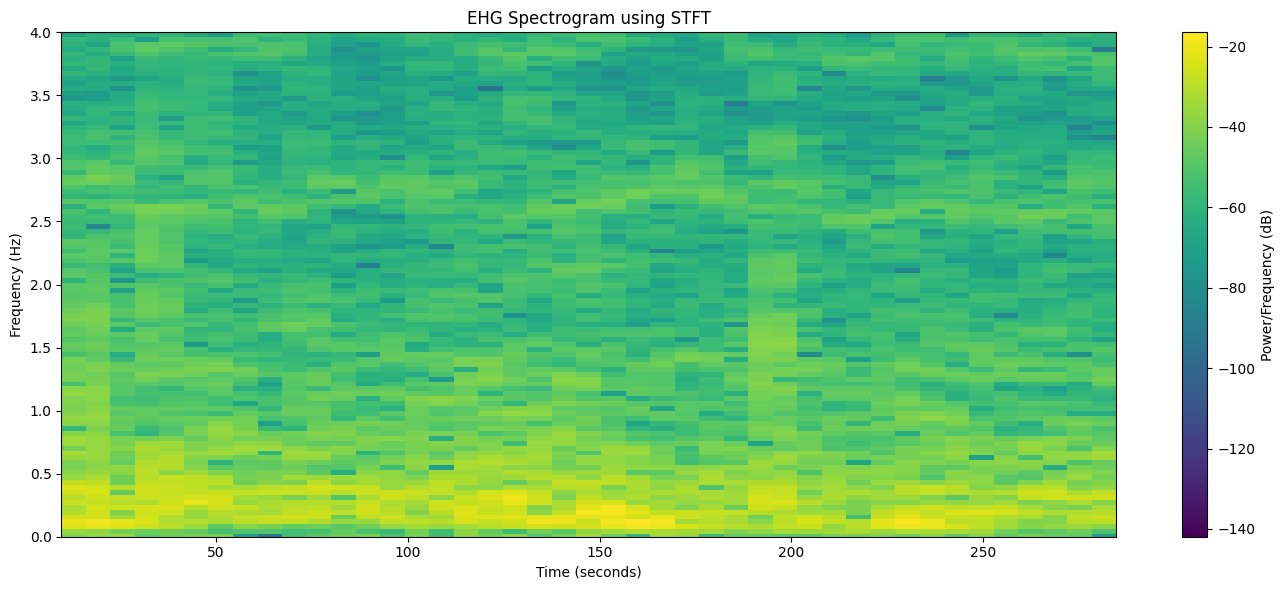

In [6]:

# Plot STFT spectrogram

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    10 * np.log10(
        np.maximum(Sxx, np.finfo(float).tiny)
    ),
    shading="auto"
)

plt.ylim(0, 4)

plt.title("EHG Spectrogram using STFT")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.colorbar(label="Power/Frequency (dB)")

plt.tight_layout()
plt.show()


In [7]:

# Select wavelet

wavelet = "cmor1.5-1.0"

# Define frequencies of interest

target_frequencies = np.linspace(
    0.08,
    4.0,
    80
)

# Convert frequencies into scales

central_frequency = pywt.central_frequency(
    wavelet
)

scales = (
    central_frequency * fs / target_frequencies
)

print("Wavelet:", wavelet)
print("Number of scales:", len(scales))
print("Frequency range:", target_frequencies[0], "-", target_frequencies[-1], "Hz")


Wavelet: cmor1.5-1.0
Number of scales: 80
Frequency range: 0.08 - 4.0 Hz


In [8]:

# Apply Continuous Wavelet Transform

coefficients, actual_frequencies = pywt.cwt(
    segment,
    scales,
    wavelet,
    sampling_period=1/fs
)

# Calculate wavelet power

wavelet_power = np.abs(coefficients)**2

print("CWT completed!")
print("Coefficient shape:", coefficients.shape)
print("Wavelet power shape:", wavelet_power.shape)


CWT completed!
Coefficient shape: (80, 6000)
Wavelet power shape: (80, 6000)


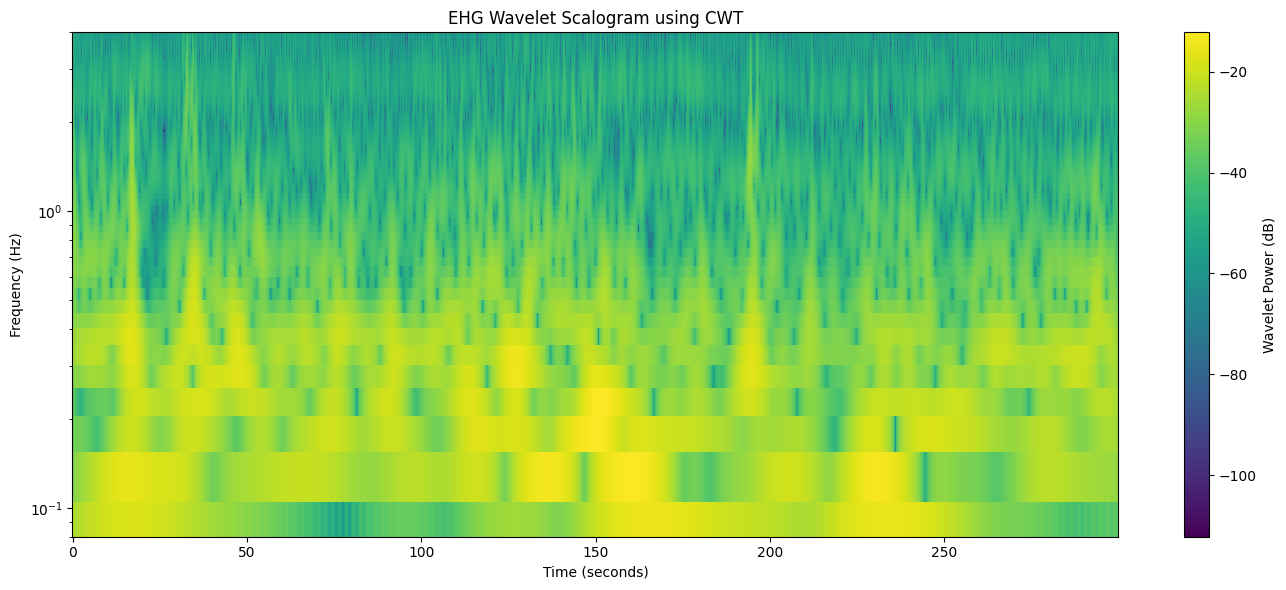

In [9]:

# Create time axis

time_axis = np.arange(len(segment)) / fs

# Plot CWT scalogram

plt.figure(figsize=(14, 6))

plt.pcolormesh(
    time_axis,
    actual_frequencies,
    10 * np.log10(
        np.maximum(
            wavelet_power,
            np.finfo(float).tiny
        )
    ),
    shading="auto"
)

plt.yscale("log")

plt.ylim(0.08, 4)

plt.title("EHG Wavelet Scalogram using CWT")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.colorbar(label="Wavelet Power (dB)")

plt.tight_layout()
plt.show()


In [10]:

# Calculate time-frequency features

mean_wavelet_power = np.mean(wavelet_power)

max_wavelet_power = np.max(wavelet_power)

# Average power across time for each frequency
average_power = np.mean(wavelet_power, axis=1)

# Find frequency with maximum average power
dominant_index = np.argmax(average_power)

dominant_wavelet_frequency = actual_frequencies[
    dominant_index
]

# Create feature dictionary

tf_features = {
    "Mean_Wavelet_Power": mean_wavelet_power,
    "Maximum_Wavelet_Power": max_wavelet_power,
    "Dominant_Wavelet_Frequency": dominant_wavelet_frequency
}

tf_df = pd.DataFrame([tf_features])

display(tf_df)


,Mean_Wavelet_Power,Maximum_Wavelet_Power,Dominant_Wavelet_Frequency
0,0.000666,0.060715,0.12962
